# 4. Final Test Set Evaluation
## Evaluating Best Model on Unseen Test Data
### **Only run this ONCE after selecting the best model from validation results**

In [1]:
import sys
sys.path.append('..')

import joblib
import pandas as pd
import matplotlib.pyplot as plt
from src.evaluation import ModelEvaluator

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

## Load Test Data

In [2]:
# Load test features
X_test_tfidf = joblib.load('../data/processed/X_test_tfidf.pkl')
X_test_bow = joblib.load('../data/processed/X_test_count.pkl')
y_test = joblib.load('../data/processed/y_test.pkl')

print(f"Test set size: {len(y_test)} samples")
print(f"TF-IDF shape: {X_test_tfidf.shape}")
print(f"BoW shape: {X_test_bow.shape}")

Test set size: 7600 samples
TF-IDF shape: (7600, 5000)
BoW shape: (7600, 5000)


## Load Validation Results to Select Best Model

In [3]:
# Load validation results
val_results = pd.read_csv('../results/comparison.csv')

print("\nValidation Results:")
print(val_results[['model_name', 'accuracy', 'f1_macro', 'f1_weighted']].to_string())

# Find best model
best_idx = val_results['accuracy'].idxmax()
best_model_info = val_results.loc[best_idx]

print("\n" + "="*60)
print("BEST MODEL (from Validation):")
print("="*60)
print(f"Model: {best_model_info['model_only']}")
print(f"Feature: {best_model_info['feature_type']}")
print(f"Validation Accuracy: {best_model_info['accuracy']:.4f}")
print(f"Validation F1-Macro: {best_model_info['f1_macro']:.4f}")


Validation Results:
                     model_name  accuracy  f1_macro  f1_weighted
0             Naive Bayes (BoW)  0.898667  0.898334     0.898334
1     Logistic Regression (BoW)  0.902667  0.902488     0.902488
2              Linear SVM (BoW)  0.905111  0.904957     0.904957
3          Naive Bayes (TF-IDF)  0.899000  0.898684     0.898684
4  Logistic Regression (TF-IDF)  0.912778  0.912627     0.912627
5           Linear SVM (TF-IDF)  0.913444  0.913261     0.913261

BEST MODEL (from Validation):
Model: Linear SVM
Feature: TF-IDF
Validation Accuracy: 0.9134
Validation F1-Macro: 0.9133


## Load Best Model

In [4]:
# Construct model filename
feature_suffix = best_model_info['feature_type'].lower().replace('-', '')
model_filename = f"../models/{best_model_info['model_only'].lower().replace(' ', '_')}_{feature_suffix}.pkl"

print(f"Loading model: {model_filename}")
best_model = joblib.load(model_filename)

# Select appropriate test features
if best_model_info['feature_type'] == 'BoW':
    X_test = X_test_bow
else:
    X_test = X_test_tfidf

print(f"Using {best_model_info['feature_type']} features for testing")

Loading model: ../models/linear_svm_tfidf.pkl
Using TF-IDF features for testing


## Evaluate on Test Set

In [5]:
# Get predictions
y_pred = best_model.predict(X_test)

# Initialize evaluator
evaluator = ModelEvaluator()

# Calculate metrics
test_metrics = evaluator.evaluate_model(y_test, y_pred, best_model_info['model_name'])

print("\n" + "="*60)
print("TEST SET RESULTS (Final Performance)")
print("="*60)
print(f"\nModel: {best_model_info['model_only']}")
print(f"Feature: {best_model_info['feature_type']}")
print(f"\nAccuracy:              {test_metrics['accuracy']:.4f}")
print(f"Precision (Macro):     {test_metrics['precision_macro']:.4f}")
print(f"Recall (Macro):        {test_metrics['recall_macro']:.4f}")
print(f"F1-Score (Macro):      {test_metrics['f1_macro']:.4f}")
print(f"F1-Score (Weighted):   {test_metrics['f1_weighted']:.4f}")


TEST SET RESULTS (Final Performance)

Model: Linear SVM
Feature: TF-IDF

Accuracy:              0.9046
Precision (Macro):     0.9044
Recall (Macro):        0.9046
F1-Score (Macro):      0.9044
F1-Score (Weighted):   0.9044


## Compare Validation vs Test Performance

In [6]:
comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Macro', 'F1-Weighted'],
    'Validation': [
        best_model_info['accuracy'],
        best_model_info['precision_macro'],
        best_model_info['recall_macro'],
        best_model_info['f1_macro'],
        best_model_info['f1_weighted']
    ],
    'Test': [
        test_metrics['accuracy'],
        test_metrics['precision_macro'],
        test_metrics['recall_macro'],
        test_metrics['f1_macro'],
        test_metrics['f1_weighted']
    ]
})

comparison_df['Difference'] = comparison_df['Test'] - comparison_df['Validation']

print("\nValidation vs Test Comparison:")
print(comparison_df.to_string(index=False))

# Check for overfitting
if comparison_df['Difference'].mean() < -0.02:
    print("\n⚠️  Warning: Model may be slightly overfitting (test performance lower than validation)")
elif abs(comparison_df['Difference'].mean()) < 0.01:
    print("\n✓ Model generalizes well (validation and test performance similar)")
else:
    print("\n✓ Model performs well on test set")


Validation vs Test Comparison:
           Metric  Validation     Test  Difference
         Accuracy    0.913444 0.904605   -0.008839
Precision (Macro)    0.913366 0.904409   -0.008956
   Recall (Macro)    0.913444 0.904605   -0.008839
         F1-Macro    0.913261 0.904421   -0.008840
      F1-Weighted    0.913261 0.904421   -0.008840

✓ Model generalizes well (validation and test performance similar)


## Detailed Per-Class Performance

In [7]:
print("\nPer-Class Metrics (Test Set):")
evaluator.print_classification_report(y_test, y_pred)


Per-Class Metrics (Test Set):
              precision    recall  f1-score   support

       World       0.92      0.90      0.91      1900
      Sports       0.95      0.98      0.96      1900
    Business       0.87      0.87      0.87      1900
    Sci/Tech       0.87      0.88      0.88      1900

    accuracy                           0.90      7600
   macro avg       0.90      0.90      0.90      7600
weighted avg       0.90      0.90      0.90      7600



## Confusion Matrix

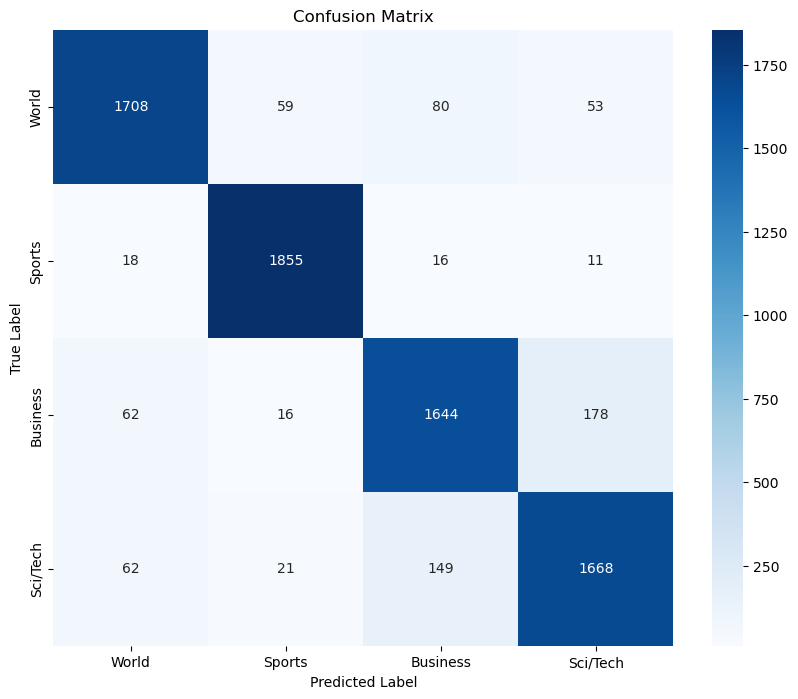

In [8]:
save_path = '../results/figures/confusion_matrix_final_test.png'
evaluator.plot_confusion_matrix(y_test, y_pred, save_path=save_path)
plt.show()

## Test All 6 Models on Test Set (Optional)

In [ ]:
print("\n" + "="*60)
print("TESTING ALL 6 MODELS ON TEST SET")
print("="*60)

all_test_results = []

for idx, row in val_results.iterrows():
    # Load model
    feature_suffix = row['feature_type'].lower().replace('-', '')
    model_filename = f"../models/{row['model_only'].lower().replace(' ', '_')}_{feature_suffix}.pkl"
    model = joblib.load(model_filename)
    
    # Select features
    if row['feature_type'] == 'BoW':
        X = X_test_bow
    else:
        X = X_test_tfidf
    
    # Predict
    y_pred = model.predict(X)
    
    # Evaluate
    metrics = evaluator.evaluate_model(y_test, y_pred, row['model_name'])
    metrics['feature_type'] = row['feature_type']
    metrics['model_only'] = row['model_only']
    
    all_test_results.append(metrics)

# Create test results dataframe
test_results_df = pd.DataFrame(all_test_results)
test_results_df = test_results_df[['model_name', 'feature_type', 'accuracy', 
                                    'precision_macro', 'recall_macro', 'f1_macro', 'f1_weighted']]

# Save test results
test_results_df.to_csv('../results/test_results.csv', index=False)

print("\nTest Set Results for All Models:")
print(test_results_df.to_string())

## Final Comparison: Validation vs Test (All Models)

In [9]:
# Merge validation and test results
merged = pd.merge(
    val_results[['model_name', 'accuracy', 'f1_macro']],
    test_results_df[['model_name', 'accuracy', 'f1_macro']],
    on='model_name',
    suffixes=('_val', '_test')
)

merged['accuracy_diff'] = merged['accuracy_test'] - merged['accuracy_val']
merged['f1_diff'] = merged['f1_macro_test'] - merged['f1_macro_val']

print("\nValidation vs Test Accuracy:")
print(merged[['model_name', 'accuracy_val', 'accuracy_test', 'accuracy_diff']].to_string())

print("\nValidation vs Test F1-Score:")
print(merged[['model_name', 'f1_macro_val', 'f1_macro_test', 'f1_diff']].to_string())

NameError: name 'test_results_df' is not defined

## Summary and Conclusion

In [10]:
print("\n" + "="*60)
print("FINAL SUMMARY")
print("="*60)

print(f"\nBest Model: {best_model_info['model_only']} with {best_model_info['feature_type']}")
print(f"\nValidation Performance:")
print(f"  Accuracy: {best_model_info['accuracy']:.4f}")
print(f"  F1-Score (Macro): {best_model_info['f1_macro']:.4f}")

print(f"\nTest Performance (Final):")
print(f"  Accuracy: {test_metrics['accuracy']:.4f}")
print(f"  F1-Score (Macro): {test_metrics['f1_macro']:.4f}")

performance_drop = (best_model_info['accuracy'] - test_metrics['accuracy']) * 100
print(f"\nPerformance Drop: {performance_drop:.2f}%")

if abs(performance_drop) < 1:
    print("✓ Excellent generalization!")
elif abs(performance_drop) < 3:
    print("✓ Good generalization")
else:
    print("⚠️  Some overfitting detected")

print(f"\n\nFiles saved:")
print(f"  - results/test_results.csv (all models on test set)")
print(f"  - results/figures/confusion_matrix_final_test.png")


FINAL SUMMARY

Best Model: Linear SVM with TF-IDF

Validation Performance:
  Accuracy: 0.9134
  F1-Score (Macro): 0.9133

Test Performance (Final):
  Accuracy: 0.9046
  F1-Score (Macro): 0.9044

Performance Drop: 0.88%
✓ Excellent generalization!


Files saved:
  - results/test_results.csv (all models on test set)
  - results/figures/confusion_matrix_final_test.png
